# Analiza kanałów
Głównym celem notatnika jest analiza, na podstawie której będzie można ustalić pipeline procesujący sygnały z warstwy bronze do warstwy silver. Kanały w pliku podzielone są na 3 kategorie - alghoritmic annotations, human annotations i physiological. Plik zawiera informacje na temat każdego kanału: nazwa kanału źródłowego (ustandaryzowany na podstawie pliku mapującego), częstotliwości sygnału i dla sygnałów physiological jednostki w jakiej był wykonywany pomiar (każde w osobnej kolumnie). Głównym problemem który trzeba rozwiązać jest fakt, że niektóre kanały z pliku mapującego występują wielokrotnie u jednego pacjenta. Konieczne jest wybranie, który będzie lepszy do dalszej analizy. 
<br>Cele analizy:
- analiza wartości brakujących i znalezienie sposobów ich rozwiązania,
- sprawdzenie konieczności ujednolicenia częstotliwości próbkowania i jednostek;
- sprawdzenie czy kanały wymagają ujednolicenia lub przeliczenia.
- rozwiązanie konfliktów i usunięcie redundantnych sygnałów;

In [1]:
import pandas as pd
import numpy as np

DATA_PATH = "/data/bronze/metadata.csv"

df = pd.read_csv(DATA_PATH)

human_cols = sorted([c for c in df.columns if '_expert' in c])
algo_cols = sorted([c for c in df.columns if '_caisr' in c])
physio_cols = sorted([c for c in df.columns if not '_expert' in c and not '_caisr' in c and c.endswith("_")])

print(f"Liczba kanałów 'human': {len(human_cols)}")
print(f"Liczba kanałów 'algorithmic': {len(algo_cols)}")
print(f"Liczba kanałów 'physiological': {len(physio_cols)}\n")

print(f"Kanały 'human': {human_cols}\n")
print(f"Kanały 'algorithmic': {algo_cols}\n")
print(f"Kanały 'physiological': {physio_cols}\n")

Liczba kanałów 'human': 4
Liczba kanałów 'algorithmic': 11
Liczba kanałów 'physiological': 35

Kanały 'human': ['freq_arousal_expert', 'freq_limb_expert', 'freq_resp_expert', 'freq_stage_expert']

Kanały 'algorithmic': ['freq_arousal_caisr', 'freq_caisr_prob_arous', 'freq_caisr_prob_n1', 'freq_caisr_prob_n2', 'freq_caisr_prob_n3', 'freq_caisr_prob_no-ar', 'freq_caisr_prob_r', 'freq_caisr_prob_w', 'freq_limb_caisr', 'freq_resp_caisr', 'freq_stage_caisr']

Kanały 'physiological': ['chin_emg_chin1_chin2_FREQ', 'chin_emg_chin_1_FREQ', 'chin_emg_chin_2_FREQ', 'ecg_ecg_FREQ', 'eeg_c3_FREQ', 'eeg_c3_m2_FREQ', 'eeg_c4_FREQ', 'eeg_c4_m1_FREQ', 'eeg_f3_FREQ', 'eeg_f3_m2_FREQ', 'eeg_f4_FREQ', 'eeg_f4_m1_FREQ', 'eeg_m1_FREQ', 'eeg_m2_FREQ', 'eeg_o1_FREQ', 'eeg_o1_m2_FREQ', 'eeg_o2_FREQ', 'eeg_o2_m1_FREQ', 'eog_e1_FREQ', 'eog_e1_m2_FREQ', 'eog_e2_FREQ', 'eog_e2_m1_FREQ', 'leg_emg_lat_FREQ', 'leg_emg_lleg_MINUS_FREQ', 'leg_emg_lleg_PLUS_FREQ', 'leg_emg_rat_FREQ', 'leg_emg_rleg_MINUS_FREQ', 'leg_emg_

## 1. Analiza braków
Przed przystąpieniem do trenowania modeli konieczne jest pozbycie się lub wypełnienie brakujących wartości w danych.
### 1.1 Braki w ocenach algorytmicznych i eksperckich

In [2]:
missing_human_data = df[human_cols].isnull().sum().to_frame(name='Brakujące wartości')
missing_human_data['Procent [%]'] = (missing_human_data['Brakujące wartości'] / len(df)) * 100

missing_alghoritmic_data = df[algo_cols].isnull().sum().to_frame(name='Brakujące wartości')
missing_alghoritmic_data['Procent [%]'] = (missing_alghoritmic_data['Brakujące wartości'] / len(df)) * 100

missing_human_data = missing_human_data.sort_values(by='Brakujące wartości', ascending=False)
missing_alghoritmic_data = missing_alghoritmic_data.sort_values(by='Brakujące wartości', ascending=False)

print("Human:")
print(missing_human_data)
print("\nAlghoritmic:")
print(missing_alghoritmic_data)

Human:
                     Brakujące wartości  Procent [%]
freq_arousal_expert                   2     0.321543
freq_limb_expert                      2     0.321543
freq_resp_expert                      2     0.321543
freq_stage_expert                     2     0.321543

Alghoritmic:
                       Brakujące wartości  Procent [%]
freq_limb_caisr                        10     1.607717
freq_resp_caisr                         7     1.125402
freq_arousal_caisr                      6     0.964630
freq_caisr_prob_n1                      6     0.964630
freq_caisr_prob_arous                   6     0.964630
freq_caisr_prob_n2                      6     0.964630
freq_caisr_prob_n3                      6     0.964630
freq_caisr_prob_r                       6     0.964630
freq_caisr_prob_no-ar                   6     0.964630
freq_caisr_prob_w                       6     0.964630
freq_stage_caisr                        6     0.964630


In [3]:
df_cleaned_step1 = df.dropna(subset=human_cols + algo_cols)

print(f"Liczba wierszy przed: {len(df)}")
print(f"Liczba wierszy po czyszczeniu: {len(df_cleaned_step1)}")
print(f"Usunięto {len(df) - len(df_cleaned_step1)} wierszy")

Liczba wierszy przed: 622
Liczba wierszy po czyszczeniu: 609
Usunięto 13 wierszy


Braki w analizach algorytmicznych i eksperckich są bardzo niewielkie (maksymalnie 1.6%). Ponadto braki w wierszach występują tylko w 13 unikalnych rekordach. Biorąc pod uwagę bardzo małą skalę występowania braków w zbiorze, pacjenci, u których one występują, zostają pominięci w dalszej analizie.
### 1.2 Braki w sygnałach physiological

In [4]:
missing_physio_data = df[physio_cols].isnull().sum().to_frame(name='Brakujące wartości')
missing_physio_data['Procent [%]'] = (missing_physio_data['Brakujące wartości'] / len(df)) * 100

print(missing_physio_data)

                           Brakujące wartości  Procent [%]
chin_emg_chin1_chin2_FREQ                 138    22.186495
chin_emg_chin_1_FREQ                      520    83.601286
chin_emg_chin_2_FREQ                      509    81.832797
ecg_ecg_FREQ                                1     0.160772
eeg_c3_FREQ                               520    83.601286
eeg_c3_m2_FREQ                            102    16.398714
eeg_c4_FREQ                               520    83.601286
eeg_c4_m1_FREQ                            108    17.363344
eeg_f3_FREQ                               520    83.601286
eeg_f3_m2_FREQ                            102    16.398714
eeg_f4_FREQ                               520    83.601286
eeg_f4_m1_FREQ                            105    16.881029
eeg_m1_FREQ                               504    81.028939
eeg_m2_FREQ                               504    81.028939
eeg_o1_FREQ                               520    83.601286
eeg_o1_m2_FREQ                            102    16.3987

W niektórych kanałach braki są ogromne (nawet 98%). Wynika to jednak z faktu, że niektóre kanały bipolarne mogą zostać wyliczone z różnicy kanałów unipolarnych. Jest to zależne od sposobu podłączenia elektrod podczas badania. Możliwe jest, więc odtworzenie brakujących danych.
#### 1.2.1 Sygnały elektrofizjologiczne podlegające rekonstrukcji

In [5]:
eeg_pairs = [
    ('eeg_c3_m2_', 'eeg_c3_', 'eeg_m2_'),
    ('eeg_c4_m1_', 'eeg_c4_', 'eeg_m1_'),
    ('eeg_f3_m2_', 'eeg_f3_', 'eeg_m2_'),
    ('eeg_f4_m1_', 'eeg_f4_', 'eeg_m1_'),
    ('eeg_o1_m2_', 'eeg_o1_', 'eeg_m2_'),
    ('eeg_o2_m1_', 'eeg_o2_', 'eeg_m1_')
]

results = []

for target, ch1, ch2 in eeg_pairs:
    target_is_null = df[target].isnull()
    sources_present = df[ch1].notnull() & df[ch2].notnull()
    can_be_calculated = target_is_null & sources_present
    missing_total = target_is_null.sum()
    recovered = can_be_calculated.sum()
    
    results.append({
        'Kanał': target,
        'Braki': missing_total,
        'Do wyliczenia': recovered,
        'Pozostałe braki': missing_total - recovered
    })

df_results = pd.DataFrame(results)
print(df_results)

            Kanał  Braki  Do wyliczenia  Pozostałe braki
0  eeg_c3_m2_FREQ    102            102                0
1  eeg_c4_m1_FREQ    108            102                6
2  eeg_f3_m2_FREQ    102            102                0
3  eeg_f4_m1_FREQ    105            102                3
4  eeg_o1_m2_FREQ    102            102                0
5  eeg_o2_m1_FREQ    110            102                8


In [6]:
eog_pairs = [
    ('eog_e1_m2_', 'eog_e1_', 'eeg_m2_'),
    ('eog_e2_m1_', 'eog_e2_', 'eeg_m1_')
]

results = []

for target, ch1, ch2 in eog_pairs:
    target_is_null = df[target].isnull()
    sources_present = df[ch1].notnull() & df[ch2].notnull()
    can_be_calculated = target_is_null & sources_present
    missing_total = target_is_null.sum()
    recovered = can_be_calculated.sum()
    
    results.append({
        'Kanał': target,
        'Braki': missing_total,
        'Do wyliczenia': recovered,
        'Pozostałe braki': missing_total - recovered
    })

df_results = pd.DataFrame(results)
print(df_results)

            Kanał  Braki  Do wyliczenia  Pozostałe braki
0  eog_e1_m2_FREQ    138            102               36
1  eog_e2_m1_FREQ    138            102               36


In [7]:
chin_pairs = [
    ('chin_emg_chin1_chin2_', 'chin_emg_chin_1_', 'chin_emg_chin_2_')
]

results = []

for target, ch1, ch2 in chin_pairs:
    target_is_null = df[target].isnull()
    sources_present = df[ch1].notnull() & df[ch2].notnull()
    can_be_calculated = target_is_null & sources_present
    missing_total = target_is_null.sum()
    recovered = can_be_calculated.sum()
    
    results.append({
        'Kanał': target,
        'Braki': missing_total,
        'Do wyliczenia': recovered,
        'Pozostałe braki': missing_total - recovered
    })

df_results_chin = pd.DataFrame(results)
print(df_results_chin)

                       Kanał  Braki  Do wyliczenia  Pozostałe braki
0  chin_emg_chin1_chin2_FREQ    138              0              138


In [8]:
leg_pairs = [
    ('leg_emg_lat_', 'leg_emg_lleg_PLUS_', 'leg_emg_lleg_MINUS_'),
    ('leg_emg_rat_', 'leg_emg_rleg_PLUS_', 'leg_emg_rleg_MINUS_')
]

results_leg = []

for target, ch1, ch2 in leg_pairs:
    target_is_null = df[target].isnull()
    sources_present = df[ch1].notnull() & df[ch2].notnull()
    can_be_calculated = target_is_null & sources_present
    missing_total = target_is_null.sum()
    recovered = can_be_calculated.sum()
    
    results_leg.append({
        'Kanał': target,
        'Braki': missing_total,
        'Do wyliczenia': recovered,
        'Pozostałe braki': missing_total - recovered
    })

df_results_leg = pd.DataFrame(results_leg)
print(df_results_leg)

              Kanał  Braki  Do wyliczenia  Pozostałe braki
0  leg_emg_lat_FREQ     14             11                3
1  leg_emg_rat_FREQ     17             11                6


Powyższe wyniki znakomicie pokazują, że zdecydowana większość braków nie jest właściwie brakami, a jedynie innym sposobem pomiaru. W przypadku sygnałów eeg, leg_emg przeliczenie z innych kanałów pokryje praktycznie większość braków występujących w zbiorze. W przypadku sygnałów chin i eog braki są znacznie większe i utrata tych rekordów byłaby znaczącą stratą danych w zbiorze uczącym.
#### 1.2.2 Sygnały oddechowe i saturacja
Według standardów AASM sygnały niektóry z sygnałów zawartych w zbiorze mogą być używane zamiennie, dzięki czemu część wybrakowanych sygnałów może zostać uzupełniona lub odrzucona na rzecz innych sygnałów bez gubienia informacji. Najważniejsze wartości wskazane w podręczniku to: 
- saturacji krwi - jedyny kanał mierzący to spo2, nie występują w nim żadne braki.
- przepływ powietrza - zgodnie z wytycznymi, do detekcji zdarzeń oddechowych rekomenduje się wykorzystywanie czujników termicznych (airflow) dla bezdechów oraz przetworników ciśnienia (ptaf) dla spłyceń. Ze względu na dużą liczbę braków w kanałach airflow i cflow do analizy zostanie wykorzystany kanał ptaf, który przez AASM jest uznawany za pierwszą alternatyę dla tych kanałów. Nieliczne braki w kanale ptaf zostaną uzupełnione przy pomocy fragmentów pozostałych kanałów.
- wysiłek oddechowy - zgodnie ze standardem, badany jest z wykorzystaniem pasów piersiowo-brzusznych, które można odczytać przy pomocy kanałów chest i abd, nie posiadają one żadnych braków.

In [9]:
import pandas as pd

resp_targets = [
    ('resp_ptaf_', 'resp_airflow_', 'resp_cflow_')
]

results_resp = []

for target, alt1, alt2 in resp_targets:
    target_is_null = df[target].isnull()
    sources_present = df[alt1].notnull() | df[alt2].notnull()
    can_be_recovered = target_is_null & sources_present
    missing_total = target_is_null.sum()
    recovered = can_be_recovered.sum()
    
    results_resp.append({
        'Kanał': target,
        'Braki': missing_total,
        'Do uzupełnienia': recovered,
        'Pozostałe braki': missing_total - recovered
    })

df_results_resp = pd.DataFrame(results_resp)
print(df_results_resp)

            Kanał  Braki  Do uzupełnienia  Pozostałe braki
0  resp_ptaf_FREQ     22                0               22


Niestety braki w kanale ptaf pokrywają się z brakami w kanałach airflow i cflow i nie mogą zostać w żaden sposób odtworzone.
### 1.3 Podsumowanie
Analiza braków wykazała, że problem brakujących kanałów, można w dużej mierze rozwiązać, dzięki wzajemnemu uzupełnianiu się aparatury pomiarowej. Scenariusz odzyskiwania to przeliczenie używając składowych kanałów unipolarnych - eeg_f3-m2 można wyliczyć z odjęcia od siebie wartości w kanałach f3 i m2. Kanału ptaf niestety nie da się odtworzyć, więc konieczne jest rozwiązanie braków w inny sposób. W celu usprawnienia potoku przetwarzania zaprojektowano scentralizowaną "tablicę prawdy", w której zawarte są wszystkie reguły przeliczania lub zastępowania kanałów. Po takim przetworzeniu znaczące braki występują jedynie w kanałach eog i chin1-chin2, w związku z czym wymagają one indywidualnego traktowania.

In [10]:
bipolar_pairs = [
    ('eeg_c3_m2_', 'eeg_c3_', 'eeg_m2_'),
    ('eeg_c4_m1_', 'eeg_c4_', 'eeg_m1_'),
    ('eeg_f3_m2_', 'eeg_f3_', 'eeg_m2_'),
    ('eeg_f4_m1_', 'eeg_f4_', 'eeg_m1_'),
    ('eeg_o1_m2_', 'eeg_o1_', 'eeg_m2_'),
    ('eeg_o2_m1_', 'eeg_o2_', 'eeg_m1_'),
    ('leg_emg_lat_', 'leg_emg_lleg_PLUS_', 'leg_emg_lleg_MINUS_'),
    ('leg_emg_rat_', 'leg_emg_rleg_PLUS_', 'leg_emg_rleg_MINUS_'),
]
 
substitution_rules = [
    ('resp_ptaf_', ['resp_airflow_', 'resp_cflow_']),
]
 
irreparable = pd.Series(False, index=df.index)
 
irreparable |= df[human_cols + algo_cols].isnull().any(axis=1)
 
for target, src1, src2 in bipolar_pairs:
    target_is_null = df[target].isnull()
    sources_present = df[src1].notnull() & df[src2].notnull()
    irreparable |= target_is_null & ~sources_present
 
for target, alternatives in substitution_rules:
    target_is_null = df[target].isnull()
    any_alt_present = df[alternatives].notnull().any(axis=1)
    irreparable |= target_is_null & ~any_alt_present
 
df_cleaned = df[~irreparable].copy()
 
print(f"Liczba wierszy przed:              {len(df)}")
print(f"Wierszy z nieodtwarzalnym brakiem: {int(irreparable.sum())}")
print(f"Liczba wierszy po czyszczeniu:     {len(df_cleaned)}")

Liczba wierszy przed:              622
Wierszy z nieodtwarzalnym brakiem: 42
Liczba wierszy po czyszczeniu:     580


Po zastosowaniu wszystkich opisanych kryteriów odrzucania i metod odtwarzana 42 pacjentów zostało wykluczonych z badania. Jest to około 6,75% wszystkich danych. Wykluczeni zostali wyłącznie pacjenci z nieodtwarzalnymi brakami w kanałach krytycznych (oceny eksperckie/algorytmiczne, sygnały EEG, EMG nóg oraz przepływ powietrza). Braki w kanałach chin i EOG, które wystąpiłyby u znacznej części pacjentów (około 20%), zostały pozostawione do indywidualnego traktowania na późniejszym etapie przetwarzania, ponieważ ich całkowite wykluczenie skutkowałoby zbyt dużą utratą danych. Z perspektywy medycznej kluczowe jest zachowanie kompletności sygnałów oddechowych i EEG, które są niezbędne do diagnostyki zaburzeń snu zgodnie ze standardami AASM. Pozostałe 93,2% zbioru stanowi solidną bazę treningową z kompletnymi danymi w kanałach krytycznych.
## 2. Analiza konfliktów
Ta część analizy skupia się na rozwiązaniu konfliktów powstałych podczas mapowania kanałów. U niektórych pacjentów słownik mapujący znalazł wiele kanałów źródłowych dla jednego ustandaryzowanego nazewnictwa. Zbadane zostaną korelacje i jakość sygnałów, aby ustalić, który z kanałów będzie najlepszy do zastosowania w dalszej analizie.

In [24]:
source_cols = [col for col in df_cleaned.columns if str(col).endswith('_SOURCE')]

mask = df_cleaned[source_cols].apply(lambda x: x.astype(str).str.contains(';', na=False)).any(axis=1)

conflicts_df = df_cleaned[mask]

conflict_cols = [col for col in df_cleaned.columns if df_cleaned[col].astype(str).str.contains(';', na=False).any()]

conflict_cols.append("SiteID")
conflict_cols.append("BidsFolder")
conflict_cols.append("SessionID")

conflicts_df = conflicts_df[conflict_cols]

display(conflicts_df)

,ecg_ecg_SOURCE,ecg_ecg_FREQ,ecg_ecg_DIM,resp_ptaf_SOURCE,resp_ptaf_FREQ,resp_ptaf_DIM,resp_airflow_SOURCE,resp_airflow_FREQ,resp_airflow_DIM,SiteID,BidsFolder,SessionID
36,EKG,200.0,uV,Nasal_Pressure,200.0,mbar,Thermistor;Flow_DR,100.0;200.0,mV;mL/s,I0006,sub-I0006179000419,1
37,EKG,200.0,uV,Nasal_Pressure,200.0,mbar,Thermistor;Flow_DR,100.0;200.0,mV;mL/s,I0006,sub-I0006179000692,1
38,EKG,200.0,uV,Nasal_Pressure,200.0,ubar,Thermistor;Flow_DR,100.0;200.0,mV;mL/s,I0006,sub-I0006179000737,1
39,EKG,200.0,uV,Nasal_Pressure,200.0,mbar,Thermistor;Flow_DR,100.0;200.0,mV;mL/s,I0006,sub-I0006179001236,1
40,EKG,200.0,uV,Nasal_Pressure,200.0,mbar,Thermistor;Flow_DR,100.0;200.0,mV;mL/s,I0006,sub-I0006179001276,1
...,...,...,...,...,...,...,...,...,...,...,...,...
339,ECG-V2;ECG-LL;ECG-V1;ECG-RA;ECG-LA,512.0;512.0;512.0;512.0;512.0,uV;uV;uV;uV;uV,Pressure;PTAF,512.0;512.0,uV;uV,Airflow2;AirFlow,512.0;512.0,uV;uV,S0001,sub-S0001120771030,1
341,ECG-V2;ECG-LL;ECG-V1;ECG-RA;ECG-LA,512.0;512.0;512.0;512.0;512.0,uV;uV;uV;uV;uV,Pressure;PTAF,512.0;512.0,uV;uV,Airflow2;AirFlow,512.0;512.0,uV;uV,S0001,sub-S0001120894407,1
363,ECG-V2;ECG-LL;ECG-V1;ECG-RA;ECG-LA,512.0;512.0;512.0;512.0;512.0,uV;uV;uV;uV;uV,Pressure;PTAF,512.0;512.0,uV;uV,Airflow2;AirFlow,512.0;512.0,uV;uV,S0001,sub-S0001121827366,1
371,ECG-V2;ECG-LL;ECG-V1;ECG-RA;ECG-LA,512.0;512.0;512.0;512.0;512.0,uV;uV;uV;uV;uV,Pressure;PTAF,512.0;512.0,uV;uV,Airflow2;AirFlow,512.0;512.0,uV;uV,S0001,sub-S0001122062477,1


Na poprzednim etapie analizy cały kanał airflow został odrzucone, więc nie będzie on poddawany analizie w tej częśći.
### 2.1 Analiza braków i niepoprawnych sgnałów
Pierwszym krokiem do ustalenia, które z kanałów powinny zostać odrzucone, jest wykrycie kanałów zawierających wybrakowane lub jednostajne sygnały, oznaczające odłączony przyrząd pomiarowy. W tym celu dla każdego z kanałów zostanie sprawdzona ilość braków w sygnale oraz jego wariancja. Dodatkowo mierzona jest wzajemna korelacja między kanałami w celu ustalenia czy sygnały są redundantne.

In [12]:
import os
from scipy.stats import spearmanr
from scipy.signal import resample
import pyedflib

base_path = "/home/emil/.cache/kagglehub/datasets/physionet/physionetchallenge2026data/versions/2/training_set/physiological_data"

def get_signal_chunk(ch, file_path, start_sec=1000, duration_sec=100):
    try:
        f = pyedflib.EdfReader(file_path)
        labels = f.getSignalLabels()
        
        if ch in labels:
            idx = labels.index(ch)
            fs = f.getSampleuency(idx)
            
            start_sample = int(start_sec * fs)
            total_samples = f.getNSamples()[idx]
            end_sample = min(start_sample + int(duration_sec * fs), total_samples)
            
            sig = f.readSignal(idx, start_sample, end_sample - start_sample)
        else:
            sig = np.array([np.nan])
            fs = 1.0
            
        f.close()
        return sig, fs
    except Exception:
        return np.array([np.nan]), 1.0

def evaluate_channel_group(channel_string, file_path):
    if pd.isna(channel_string):
        return channel_string, {}
        
    channels = [ch.strip() for ch in str(channel_string).split(';')]
    if len(channels) == 1:
        return channels[0], {}
    
    metrics = []
    out_dict = {}
    
    for i, ch in enumerate(channels, start=1):
        sig, fs = get_signal_chunk(ch, file_path, start_sec=1000, duration_sec=100)
        
        if len(sig) == 0:
            nan_ratio = 1.0
        else:
            nan_ratio = np.isnan(sig).sum() / len(sig)
            
        variance = float(np.var(sig[~np.isnan(sig)])) if nan_ratio < 1.0 else 0.0
        
        metrics.append({
            'channel': ch,
            'nan_ratio': nan_ratio,
            'variance': variance,
            'signal': sig,
            'fs': fs
        })
        
        out_dict[f'ch{i}_name'] = ch
        out_dict[f'ch{i}_nan_ratio'] = round(nan_ratio, 4)
        out_dict[f'ch{i}_variance'] = round(variance, 4)
    
    df_metrics = pd.DataFrame(metrics)
    valid_candidates = df_metrics[(df_metrics['nan_ratio'] < 0.5) & (df_metrics['variance'] > 0.01)].copy()
    
    if valid_candidates.empty:
        out_dict['correlation'] = None
        return None, out_dict
    
    if len(valid_candidates) == 1:
        out_dict['correlation'] = None
        return valid_candidates.iloc[0]['channel'], out_dict
    
    target_fs = int(valid_candidates['fs'].max())
    target_len = int(100 * target_fs)
    
    resampled_signals = []
    for _, row in valid_candidates.iterrows():
        s = row['signal']
        if row['fs'] != target_fs and len(s) > 1:
            s = resample(s, target_len)
        elif len(s) < target_len:
            s = np.pad(s, (0, max(0, target_len - len(s))), mode='edge')[:target_len]
        resampled_signals.append(s[:target_len])
        
    signals_matrix = np.vstack(resampled_signals)
    if signals_matrix.shape[0] > 1:
        corr_val, _ = spearmanr(signals_matrix, axis=1)
        if isinstance(corr_val, np.ndarray):
            out_dict['correlation'] = np.round(corr_val, 4).tolist()
        else:
            out_dict['correlation'] = round(float(corr_val), 4)
    else:
        out_dict['correlation'] = None
        
    best_channel = valid_candidates.sort_values(by=['nan_ratio', 'variance'], ascending=[True, False]).iloc[0]
    
    return best_channel['channel'], out_dict

def analyze_source_conflicts(df, source_column, base_path):
    results = []
    
    for index, row in df.iterrows():
        channel_string = str(row.get(source_column, ''))
        
        if ';' in channel_string:
            site_id = row.get('SiteID')
            bids_folder = row.get('BidsFolder')
            session_id = row.get('SessionID', '1') 
            
            file_name = f"{bids_folder}_ses-{session_id}.edf"
            file_path = os.path.join(base_path, str(site_id), file_name)
            
            if not os.path.exists(file_path):
                continue
                
            best_ch, criteria = evaluate_channel_group(channel_string, file_path)
            
            result_row = {
                'BidsFolder': bids_folder,
                'Conflict': channel_string,
                'ResolvedChannel': best_ch
            }
            result_row.update(criteria)
            results.append(result_row)
            
    return pd.DataFrame(results)

df_ecg = analyze_source_conflicts(df_cleaned, 'ecg_ecg_SOURCE', base_path)
df_ptaf = analyze_source_conflicts(df_cleaned, 'resp_ptaf_SOURCE', base_path)

display(df_ptaf)
display(df_ecg)

,BidsFolder,Conflict,ResolvedChannel,ch1_name,ch1_nan_ratio,ch1_variance,ch2_name,ch2_nan_ratio,ch2_variance,correlation
0,sub-I0006179017187,Pressure;Nasal_Pressure,Pressure,Pressure,0.0,0.0926,Nasal_Pressure,1.0,0.0000,NaN
1,sub-S0001111243686,Pressure;PTAF,Pressure,Pressure,0.0,4.7531,PTAF,0.0,3.9453,-0.6342
2,sub-S0001113935673,Pressure;PTAF,Pressure,Pressure,0.0,80.5210,PTAF,0.0,8.3589,-0.9637
3,sub-S0001114377479,Pressure;PTAF,Pressure,Pressure,0.0,77.9539,PTAF,0.0,8.5855,-0.9544
4,sub-S0001117197081,Pressure;PTAF,PTAF,Pressure,0.0,2.1939,PTAF,0.0,2.8028,-0.4496
5,sub-S0001118093423,Pressure;PTAF,None,Pressure,0.0,0.0000,PTAF,0.0,0.0000,NaN
6,sub-S0001118516760,Pressure;PTAF,Pressure,Pressure,0.0,28.1192,PTAF,0.0,5.8274,-0.9645
7,sub-S0001120771030,Pressure;PTAF,Pressure,Pressure,0.0,428.2392,PTAF,0.0,40.7281,-0.6444
8,sub-S0001120894407,Pressure;PTAF,Pressure,Pressure,0.0,2.1734,PTAF,0.0,1.4991,-0.8915
9,sub-S0001121827366,Pressure;PTAF,Pressure,Pressure,0.0,14.4041,PTAF,0.0,3.9304,-0.6549


,BidsFolder,Conflict,ResolvedChannel,ch1_name,ch1_nan_ratio,ch1_variance,ch2_name,ch2_nan_ratio,ch2_variance,ch3_name,ch3_nan_ratio,ch3_variance,ch4_name,ch4_nan_ratio,ch4_variance,ch5_name,ch5_nan_ratio,ch5_variance,correlation
0,sub-S0001111243686,ECG-V2;ECG-LL;ECG-V1;ECG-RA;ECG-LA,ECG-V1,ECG-V2,0.0,7.391031e+04,ECG-LL,0.0,7.336971e+04,ECG-V1,0.0,7.393201e+04,ECG-RA,0.0,63049.2152,ECG-LA,0.0,2.105936e+04,"[[1.0, 0.9985, 0.9985, -0.7672, -0.9532], [0.9..."
1,sub-S0001113935673,ECG-V2;ECG-LL;ECG-V1;ECG-RA;ECG-LA,ECG-V1,ECG-V2,0.0,3.140498e+04,ECG-LL,0.0,3.183495e+04,ECG-V1,0.0,3.199502e+04,ECG-RA,0.0,6912.4479,ECG-LA,0.0,9.537365e+03,"[[1.0, 0.9974, 0.9974, -0.8542, -0.75], [0.997..."
2,sub-S0001114377479,ECG-V2;ECG-LL;ECG-V1;ECG-RA;ECG-LA,ECG-V2,ECG-V2,0.0,5.099718e+06,ECG-LL,0.0,5.062482e+06,ECG-V1,0.0,5.098682e+06,ECG-RA,0.0,24631.4974,ECG-LA,0.0,6.804462e+04,"[[1.0, 0.9999, 0.9999, -0.9419, -0.8293], [0.9..."
3,sub-S0001117197081,ECG-V2;ECG-LL;ECG-V1;ECG-RA;ECG-LA,ECG-LA,ECG-V2,0.0,6.659121e+03,ECG-LL,0.0,6.494683e+03,ECG-V1,0.0,6.450027e+03,ECG-RA,0.0,17679.0933,ECG-LA,0.0,6.170147e+04,"[[1.0, 0.9894, 0.9858, -0.6985, -0.5293], [0.9..."
4,sub-S0001118093423,ECG-V2;ECG-LL;ECG-V1;ECG-RA;ECG-LA,None,ECG-V2,0.0,0.000000e+00,ECG-LL,0.0,0.000000e+00,ECG-V1,0.0,0.000000e+00,ECG-RA,0.0,0.0000,ECG-LA,0.0,0.000000e+00,None
5,sub-S0001118516760,ECG-V2;ECG-LL;ECG-V1;ECG-RA;ECG-LA,ECG-LA,ECG-V2,0.0,6.456072e+03,ECG-LL,0.0,5.736061e+03,ECG-V1,0.0,5.600864e+03,ECG-RA,0.0,6567.5115,ECG-LA,0.0,1.326929e+04,"[[1.0, 0.8285, 0.8581, -0.4558, -0.4149], [0.8..."
6,sub-S0001120771030,ECG-V2;ECG-LL;ECG-V1;ECG-RA;ECG-LA,ECG-RA,ECG-V2,0.0,4.887027e+04,ECG-LL,0.0,4.995819e+04,ECG-V1,0.0,4.921832e+04,ECG-RA,0.0,133988.4022,ECG-LA,0.0,1.274344e+05,"[[1.0, 0.9985, 0.9982, -0.9343, -0.8559], [0.9..."
7,sub-S0001120894407,ECG-V2;ECG-LL;ECG-V1;ECG-RA;ECG-LA,ECG-RA,ECG-V2,0.0,3.850595e+02,ECG-LL,0.0,3.419782e+02,ECG-V1,0.0,3.834530e+02,ECG-RA,0.0,307289.5044,ECG-LA,0.0,2.589804e+04,"[[1.0, 0.914, 0.9202, -0.2912, -0.4749], [0.91..."
8,sub-S0001121827366,ECG-V2;ECG-LL;ECG-V1;ECG-RA;ECG-LA,ECG-V2,ECG-V2,0.0,5.066918e+07,ECG-LL,0.0,5.065271e+07,ECG-V1,0.0,5.066707e+07,ECG-RA,0.0,233039.7782,ECG-LA,0.0,1.876468e+06,"[[1.0, 0.9986, 0.9997, 0.3529, 0.2753], [0.998..."
9,sub-S0001122062477,ECG-V2;ECG-LL;ECG-V1;ECG-RA;ECG-LA,ECG-V2,ECG-V2,0.0,5.175348e+06,ECG-LL,0.0,5.140709e+06,ECG-V1,0.0,5.156222e+06,ECG-RA,0.0,92562.0583,ECG-LA,0.0,5.566601e+05,"[[1.0, 0.9999, 0.9999, -0.9599, -0.7707], [0.9..."


Analiza konfliktów wykazała, że dublujące się kanały oddechowe rejestrują dokładnie to samo zjawisko fizjologiczne, a ich silnie ujemna korelacja wynika jedynie z odwróconej polaryzacji aparatury. Z faktu, że w zdecydowanej większości zbioru pacjenci mają wyłącznie kanał ptaf, do dalszej analizy priorytetowo będzie brany kanał PTAF. W przypadku, w których kanał PTAF nie występuje (wiersz 0), kanał pressure jest jedynym niepustym kanałem i to on zostanie wzięty do dalszego przetwarzania. Przypadek, w którym oba kanały są jednostajne (wiersz 5), zostaje wykluczony ze zbioru.

Analiza sygnałów EKG pokazała, że wybór kanału na podstawie najwyższej wariancji to w tym przypadku zły pomysł. W EKG ogromna wariancja nie oznacza czystego zapisu, ale duże zaszumienie. Z kolei ujemna korelacja elektrody prawego ramienia (RA) z pozostałymi to nie błąd sprzętu, lecz naturalny wynik anatomii serca i kierunku przepływu prądu. Dane EKG wymagają zupełnie innego podejścia i zbadania innych kryteriów. Główny wniosek, jaki można wyciągnąć z tej części analizy, to fakt, że wariancja przydaje się tu wyłącznie do wykrywania odłączonych elektrod – pozwoliła ona skutecznie zidentyfikować pacjenta z całkowicie jednostajnymi sygnałami (wiersz 4), u którego w ogóle nie zarejestrowano EKG.
### 2.2 Analiza jakości sygnałów EKG
W celu weryfikacji jakości tych sygnałów przyjęta zostaja miara oparta na statystykach wyższych rzędów (HOS – Higher-Order Statistics), a w szczególności na kurtozie i skośności. W przeciwieństwie do wariancji, która wzrasta przy dowolnych dużych wahaniach amplitudy, metryki te oceniają sam kształt rozkładu sygnału. Skośność mierzy jego asymetrię, co pozwala zidentyfikować jednokierunkowe wychylenia typowe dla kardiologicznych załamków. Z kolei kurtoza określa stopień wysklepienia rozkładu – jej wysokie wartości jednoznacznie wskazują na obecność rzadkich, ostrych pików (zespołów QRS) na tle płaskiej linii izoelektrycznej, pozwalając skutecznie odróżnić sygnał użyteczny od bezużytecznego szumu.

In [13]:
from scipy.stats import skew, kurtosis

def compute_global_sqi(sig):
    sig_clean = sig[~np.isnan(sig)]
    if len(sig_clean) < 10:
        return np.nan, np.nan, np.nan
    sqi_skew = skew(sig_clean)
    sqi_kur = kurtosis(sig_clean, fisher=False)
    sqi_hos = sqi_kur * np.abs(sqi_skew)
    return sqi_skew, sqi_kur, sqi_hos

def process_ecg_dataframe(df_ecg, base_path):
    df_conflict = df_ecg[df_ecg['ecg_ecg_SOURCE'].astype(str).str.contains(';', na=False)].copy()
    
    best_channels = []
    best_kur_vals = []
    best_skew_vals = []
    best_hos_vals = []
    
    all_kur_dicts = []
    all_skew_dicts = []
    all_hos_dicts = []
    
    for idx, row in df_conflict.iterrows():
        bids_folder = row['BidsFolder']
        site_id = row['SiteID']
        
        session_id = row.get('sessionId', row.get('SessionID', '1'))
        if pd.isna(session_id):
            session_id = '1'
            
        file_name = f"{bids_folder}_ses-{session_id}.edf"
        file_path = os.path.join(base_path, str(site_id), file_name)
        
        sources_raw = row['ecg_ecg_SOURCE']
        sources = str(sources_raw).split(';')
        
        best_ch = None
        max_hos = -np.inf
        b_kur = np.nan
        b_skew = np.nan
        
        ch_kur_dict = {}
        ch_skew_dict = {}
        ch_hos_dict = {}
        
        for ch in sources:
            ch = ch.strip()
            sig, fs = get_signal_chunk(ch, file_path, start_sec=1000, duration_sec=100)
            s_skew, s_kur, s_hos = compute_global_sqi(sig)
            
            ch_kur_dict[ch] = s_kur
            ch_skew_dict[ch] = s_skew
            ch_hos_dict[ch] = s_hos
            
            if not np.isnan(s_hos) and s_hos > max_hos:
                max_hos = s_hos
                best_ch = ch
                b_kur = s_kur
                b_skew = s_skew
                
        best_channels.append(best_ch)
        best_kur_vals.append(b_kur)
        best_skew_vals.append(b_skew)
        best_hos_vals.append(max_hos if max_hos != -np.inf else np.nan)
        
        all_kur_dicts.append(ch_kur_dict)
        all_skew_dicts.append(ch_skew_dict)
        all_hos_dicts.append(ch_hos_dict)
        
    df_conflict['ResolvedChannel'] = best_channels
    df_conflict['SQI_kur'] = best_kur_vals
    df_conflict['SQI_skew'] = best_skew_vals
    df_conflict['SQI_hos'] = best_hos_vals
    
    df_conflict['All_SQI_kur'] = all_kur_dicts
    df_conflict['All_SQI_skew'] = all_skew_dicts
    df_conflict['All_SQI_hos'] = all_hos_dicts
    
    return df_conflict
ecg_processed = process_ecg_dataframe(conflicts_df , base_path)
display(ecg_processed[['BidsFolder', 'SiteID', 'ecg_ecg_SOURCE', 'ResolvedChannel', 'SQI_skew', 'SQI_kur', 'SQI_hos', 'All_SQI_hos', 'All_SQI_kur', 'All_SQI_skew']])

/tmp/ipykernel_23837/2896068127.py:7: RuntimeWarning: Precision loss occurred in moment calculation due to catastrophic cancellation. This occurs when the data are nearly identical. Results may be unreliable.
  sqi_skew = skew(sig_clean)
/tmp/ipykernel_23837/2896068127.py:8: RuntimeWarning: Precision loss occurred in moment calculation due to catastrophic cancellation. This occurs when the data are nearly identical. Results may be unreliable.
  sqi_kur = kurtosis(sig_clean, fisher=False)


,BidsFolder,SiteID,ecg_ecg_SOURCE,ResolvedChannel,SQI_skew,SQI_kur,SQI_hos,All_SQI_hos,All_SQI_kur,All_SQI_skew
141,sub-S0001111243686,S0001,ECG-V2;ECG-LL;ECG-V1;ECG-RA;ECG-LA,ECG-RA,-2.555556,14.083220,35.990451,"{'ECG-V2': 0.04446633772143812, 'ECG-LL': 0.04...","{'ECG-V2': 1.668893724053584, 'ECG-LL': 1.6745...","{'ECG-V2': -0.02664419973575886, 'ECG-LL': -0...."
190,sub-S0001113935673,S0001,ECG-V2;ECG-LL;ECG-V1;ECG-RA;ECG-LA,ECG-LA,-0.252055,3.345077,0.843144,"{'ECG-V2': 0.020306410218648686, 'ECG-LL': 0.0...","{'ECG-V2': 1.646750425932939, 'ECG-LL': 1.6599...","{'ECG-V2': -0.012331200829745908, 'ECG-LL': -0..."
198,sub-S0001114377479,S0001,ECG-V2;ECG-LL;ECG-V1;ECG-RA;ECG-LA,ECG-LA,-0.829952,5.698345,4.729351,"{'ECG-V2': 0.13861205826966047, 'ECG-LL': 0.13...","{'ECG-V2': 1.694812916445647, 'ECG-LL': 1.6960...","{'ECG-V2': -0.08178605256346345, 'ECG-LL': -0...."
268,sub-S0001117197081,S0001,ECG-V2;ECG-LL;ECG-V1;ECG-RA;ECG-LA,ECG-LA,-2.655222,17.530577,46.547573,"{'ECG-V2': 0.045489621713599784, 'ECG-LL': 0.0...","{'ECG-V2': 1.9390734303199129, 'ECG-LL': 1.877...","{'ECG-V2': -0.023459463165402046, 'ECG-LL': -0..."
289,sub-S0001118093423,S0001,ECG-V2;ECG-LL;ECG-V1;ECG-RA;ECG-LA,None,NaN,NaN,NaN,"{'ECG-V2': nan, 'ECG-LL': nan, 'ECG-V1': nan, ...","{'ECG-V2': nan, 'ECG-LL': nan, 'ECG-V1': nan, ...","{'ECG-V2': nan, 'ECG-LL': nan, 'ECG-V1': nan, ..."
302,sub-S0001118516760,S0001,ECG-V2;ECG-LL;ECG-V1;ECG-RA;ECG-LA,ECG-LA,-1.487730,8.031074,11.948074,"{'ECG-V2': 0.22236868644395152, 'ECG-LL': 0.01...","{'ECG-V2': 1.8143448785605631, 'ECG-LL': 1.688...","{'ECG-V2': 0.12256142096885733, 'ECG-LL': -0.0..."
339,sub-S0001120771030,S0001,ECG-V2;ECG-LL;ECG-V1;ECG-RA;ECG-LA,ECG-LA,-0.310041,3.305501,1.024839,"{'ECG-V2': 0.06727454422849515, 'ECG-LL': 0.06...","{'ECG-V2': 1.878801607353024, 'ECG-LL': 1.8496...","{'ECG-V2': -0.035807157054371395, 'ECG-LL': -0..."
341,sub-S0001120894407,S0001,ECG-V2;ECG-LL;ECG-V1;ECG-RA;ECG-LA,ECG-LA,-0.455605,2.431157,1.107647,"{'ECG-V2': 0.32137318496607997, 'ECG-LL': 0.26...","{'ECG-V2': 1.8531616425373318, 'ECG-LL': 1.825...","{'ECG-V2': 0.17341886297951795, 'ECG-LL': 0.14..."
363,sub-S0001121827366,S0001,ECG-V2;ECG-LL;ECG-V1;ECG-RA;ECG-LA,ECG-LL,0.673530,1.650365,1.111570,"{'ECG-V2': 1.1098390558697473, 'ECG-LL': 1.111...","{'ECG-V2': 1.6494206030496452, 'ECG-LL': 1.650...","{'ECG-V2': 0.6728660075045411, 'ECG-LL': 0.673..."
371,sub-S0001122062477,S0001,ECG-V2;ECG-LL;ECG-V1;ECG-RA;ECG-LA,ECG-LA,0.071874,1.939341,0.139388,"{'ECG-V2': 0.03138497131019477, 'ECG-LL': 0.03...","{'ECG-V2': 1.6999713198752786, 'ECG-LL': 1.689...","{'ECG-V2': -0.018462059296681186, 'ECG-LL': -0..."


Zdecydowanym faworytem wśród badanych kanałów okazał się ECG-LA, czyli sygnał z elektrody lewego ramienia. Wynika to z anatomii – mięsień lewej komory jest najgrubszy, co przekłada się na najbardziej wyraźne odchyły sygnału z tej strony. W dalszej analizie zostanie sprawdzone, czy u dwóch pacjentów, u których algorytm wskazał inne kanały jako najlepsze, uzasadnione jest zrezygnowanie z globalnego ujednolicenia źródła sygnału.

In [14]:
with pd.option_context('display.max_colwidth', None):
    display(ecg_processed[ecg_processed['ResolvedChannel'] != 'ECG-LA'][['ResolvedChannel', 'All_SQI_hos', 'All_SQI_kur', 'All_SQI_skew']].dropna())

,ResolvedChannel,All_SQI_hos,All_SQI_kur,All_SQI_skew
141,ECG-RA,"{'ECG-V2': 0.04446633772143812, 'ECG-LL': 0.044995802683522934, 'ECG-V1': 0.0438359957405869, 'ECG-RA': 35.99045117715636, 'ECG-LA': 0.12895751335081987}","{'ECG-V2': 1.668893724053584, 'ECG-LL': 1.6745309310339733, 'ECG-V1': 1.668561823019785, 'ECG-RA': 14.08321970871413, 'ECG-LA': 1.4860678095187845}","{'ECG-V2': -0.02664419973575886, 'ECG-LL': -0.02687069068096542, 'ECG-V1': -0.026271724029530978, 'ECG-RA': -2.555555613102231, 'ECG-LA': 0.08677767765696953}"
363,ECG-LL,"{'ECG-V2': 1.1098390558697473, 'ECG-LL': 1.1115696714911, 'ECG-V1': 1.1099215237098827, 'ECG-RA': 0.01889068688538785, 'ECG-LA': 0.07376157471808943}","{'ECG-V2': 1.6494206030496452, 'ECG-LL': 1.650365119411176, 'ECG-V1': 1.6494488331711055, 'ECG-RA': 1.2682971253666524, 'ECG-LA': 1.909431265784293}","{'ECG-V2': 0.6728660075045411, 'ECG-LL': 0.673529547139054, 'ECG-V1': 0.6729044886927663, 'ECG-RA': -0.014894527873290523, 'ECG-LA': -0.03863012826900166}"


W przypadku pacjenta 141 rezygnacja na rzecz kanału ECG-RA jest w pełni uzasadniona, jest to jedyny kanał z zestawu, w którym sygnał jest wyraźny i cechuje się charakterystycznymi dla EKG ostrymi pikami na tle "płaskiej linii". Z kolei u pacjenta 363 właściwie żaden kanał nie dostarcza odpowiedniego jakościowo sygnału. Kanał LA ma trochę wyższy współczynnik kurtozy, jednak ma bardzo niski skew, co oznacza, że jest prawie symetryczny, co w standardowym badaniu EKG nie powinno występować. Wybór LL jest również uzasadniony, a mechanizm wyboru kanału na podstawie wcześniej wymienionych kryteriów zostanie zaimplementowany do pipelinu procesującego z warstwy bronze do warstwy silver.
### 2.3 Podsumowanie
Po odrzuceniu wszystkich kanałów z rodzaju Airflow skala konfliktów okazała się być naprawdę nieduża. W kanałych ptaf występuje silna korelacja między kanałami źródłowymi, więc w celu ujednolicenia źródła danych przyjmujemy hierarchię, w której priorytetyzujemy kanał ptaf nad pozostałhymi. Głębsza analiza kanałów ekg wykazała, że kanały te mogą zawierać sygnały o róźnym rozkładzie statystycznym, a co za tym idzie - o różnej jakości. Pipeline procesujący w tym wypadku będzie musiał policzyć kryteria, na podstawie których podejmie decyzję, który kanał powiniene znaleźć się w dalszej analizie.
## 3. Częstotliwość próbkowania i jednostki
Ta część skupia się na analizie częstotliwości próbek oraz wykształceniu reguł przepróbkowania i przeliczania jednostek. Pozwoli to na ujednolicenie danych źródłowych, co jest niezbędne do późniejszej ekstrakcji cech.
### 3.1 Oceny algorytmiczne i eskperckie

In [15]:
algo_cols = [c for c in df_cleaned.columns if 'caisr' in c]
human_cols = [c for c in df_cleaned.columns if 'expert' in c]
all_target_cols = algo_cols + human_cols

summary_df = pd.DataFrame({
    'Unique Values': [df_cleaned[col].dropna().unique().tolist() for col in all_target_cols],
}, index=all_target_cols)

print(summary_df)

                              Unique Values
freq_arousal_caisr                    [2.0]
freq_caisr_prob_no-ar                 [2.0]
freq_caisr_prob_arous                 [2.0]
freq_limb_caisr                       [1.0]
freq_resp_caisr                       [1.0]
freq_stage_caisr       [0.0333333333333333]
freq_caisr_prob_n3     [0.0333333333333333]
freq_caisr_prob_n2     [0.0333333333333333]
freq_caisr_prob_n1     [0.0333333333333333]
freq_caisr_prob_r      [0.0333333333333333]
freq_caisr_prob_w      [0.0333333333333333]
freq_arousal_expert                   [2.0]
freq_limb_expert                      [1.0]
freq_resp_expert                      [1.0]
freq_stage_expert      [0.0333333333333333]


Wszytskie sygnały, zarówno z analizy eksperckiej jak i z analizy algorytmicznej, mają jednolitą częstotliwość u każdego pacjenta. Ponadto odpowiadające sobie kanały z analiz eksperckich i algorytmicznych mają taką samą częstotliwość próbkowania. Oznacza to, że te kanały są idealnie przygotowane do późniejszego przetwarzania oraz porównania i nie wymagają żadnego przeprópkowania.

## 3.2 Sygnały physiological
Sygnały physiological charakteryzują się dużą odmiennością. Róźne rodzaje sygnałów mają róźną zaleconą częstotliwość i jednostki, co oznacza, że każdy rodzaj sygnału wymaga indywidualnej analizy, przepróbkowania i przeliczenia.
## 3.2.1 Kanały EEG

In [16]:
eeg_ = [c for c in df_cleaned.columns if 'eeg' in c and c.endswith("_")]
eeg_dim = [c for c in df_cleaned.columns if 'eeg' in c and c.endswith("_DIM")]

summary_df = pd.DataFrame({
    'Unique uency': [df_cleaned[col].dropna().unique().tolist() for col in eeg_],
    'Unique Dimensions': [df_cleaned[col].dropna().unique().tolist() for col in eeg_dim]
}, index=eeg_)

print(summary_df)

                            Unique Frequency Unique Dimensions
eeg_f3_m2_FREQ  [500.0, 200.0, 512.0, 250.0]              [uV]
eeg_f4_m1_FREQ  [500.0, 200.0, 512.0, 250.0]              [uV]
eeg_c3_m2_FREQ  [500.0, 200.0, 512.0, 250.0]              [uV]
eeg_c4_m1_FREQ  [500.0, 200.0, 512.0, 250.0]              [uV]
eeg_o1_m2_FREQ  [500.0, 200.0, 512.0, 250.0]              [uV]
eeg_o2_m1_FREQ  [500.0, 200.0, 512.0, 250.0]              [uV]
eeg_m1_FREQ            [200.0, 512.0, 250.0]              [uV]
eeg_m2_FREQ            [200.0, 512.0, 250.0]              [uV]
eeg_f3_FREQ                          [200.0]              [uV]
eeg_f4_FREQ                          [200.0]              [uV]
eeg_c3_FREQ                          [200.0]              [uV]
eeg_c4_FREQ                          [200.0]              [uV]
eeg_o1_FREQ                          [200.0]              [uV]
eeg_o2_FREQ                          [200.0]              [uV]


Wszystkie kanały EEG u wszystkich pacjentów są mierzone w uV, więc nie wymagają one żadnych przekształceń. Z kolei częstotliwości już nie są ustandaryzowane i wahają się w granicach 200 - 512 Hz. W celu zbadania ilości sygnałów nagranych w poszczególnych częstotliwościach stworzono wykresy słupkowe.

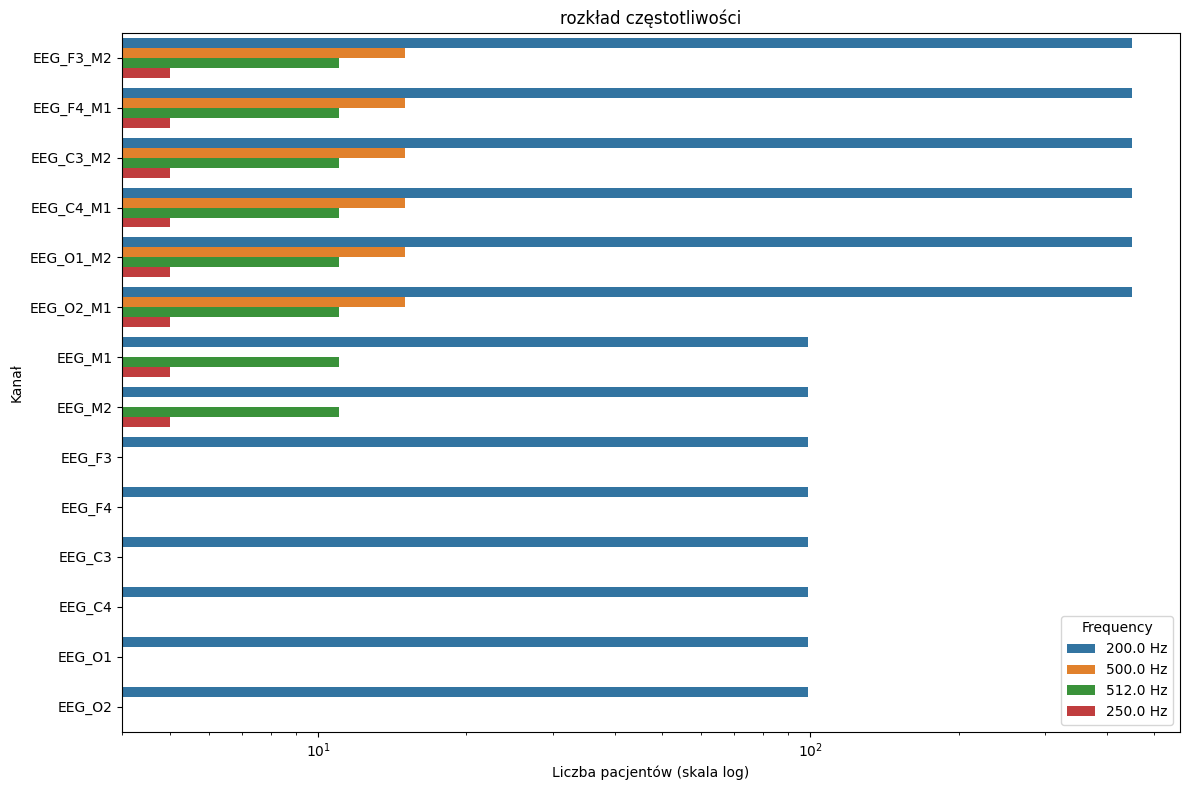

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

def plot_sampling_uencies(df, columns):
    _data = []
    for col in columns:
        counts = df[col].value_counts()
        clean_name = col.replace('_', '').upper()
        for , count in counts.items():
            _data.append({
                'Channel': clean_name,
                'uency': str() + ' Hz',
                'Count': count
            })
            
    plot_df = pd.DataFrame(_data)
    plt.figure(figsize=(12, 8))
    
    sns.barplot(data=plot_df, x='Count', y='Channel', hue='uency')
    plt.xscale('log')
    
    plt.title("rozkład częstotliwości")
    plt.xlabel('Liczba pacjentów (skala log)')
    plt.ylabel('Kanał')
    plt.tight_layout()
    plt.show()

eeg_cols = [
    'eeg_f3_m2_', 'eeg_f4_m1_', 'eeg_c3_m2_', 'eeg_c4_m1_',
    'eeg_o1_m2_', 'eeg_o2_m1_', 'eeg_m1_', 'eeg_m2_',
    'eeg_f3_', 'eeg_f4_', 'eeg_c3_', 'eeg_c4_',
    'eeg_o1_', 'eeg_o2_'
]

plot_sampling_uencies(df_cleaned, eeg_cols)

Wykresy jednoznacznie pokazują znaczną przewagę pomiarów wykonanych w częstotliwości 200Hz. AASM zaleca tę częstotliwość jako minimalną w analizie sygnałów EEG, dlatego najbardziej optymalnym krokiem w procesie przygotowania danych będzie zastosowanie downsamplingu dla rzadszych sygnałów o wyższych częstotliwościach w celu ujednolicenia całego zbioru do tej wspólnej bazy 200 Hz. Zapewni niezbędną spójność wymiarową potoku przetwarzania bez start w jakości sygnałów.
### 3.2.2 Pozostałe kanały elektrofizjologiczne (EOG, EMG, ECG)

In [18]:
target_cols = [c for c in df_cleaned.columns if any(k in c for k in ['eog', 'ecg', 'ekg', 'emg']) and c.endswith("_")]
dim_cols = [c.replace("_", "_DIM") for c in target_cols]

summary_df = pd.DataFrame({
    'Unique uency': [df_cleaned[col].dropna().unique().tolist() for col in target_cols],
    'Unique Dimensions': [df_cleaned[c].dropna().unique().tolist() if c in df_cleaned.columns else [] for c in dim_cols]
}, index=target_cols)

print(summary_df)

                                                            Unique Frequency  \
eog_e1_FREQ                                                   [500.0, 200.0]   
eog_e2_FREQ                                                   [500.0, 200.0]   
eog_e2_m1_FREQ                                         [200.0, 512.0, 250.0]   
eog_e1_m2_FREQ                                         [200.0, 512.0, 250.0]   
chin_emg_chin1_chin2_FREQ                       [500.0, 200.0, 512.0, 250.0]   
chin_emg_chin_1_FREQ                                                 [200.0]   
chin_emg_chin_2_FREQ                                          [200.0, 512.0]   
leg_emg_lat_FREQ                                       [500.0, 200.0, 250.0]   
leg_emg_rat_FREQ                                       [500.0, 200.0, 250.0]   
leg_emg_rleg_PLUS_FREQ                                               [512.0]   
leg_emg_rleg_MINUS_FREQ                                              [512.0]   
leg_emg_lleg_PLUS_FREQ                  

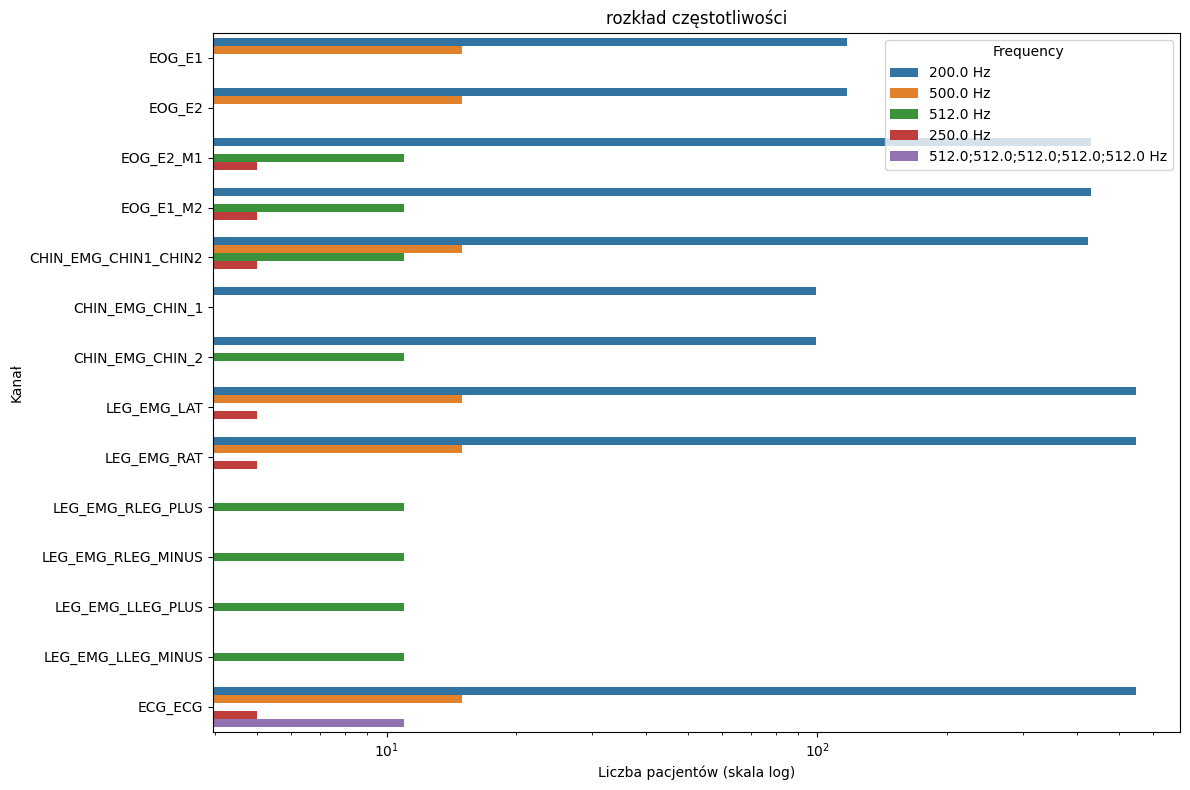

In [19]:
e_cols = [
    'eog_e1_',
    'eog_e2_',
    'eog_e2_m1_',
    'eog_e1_m2_',
    'chin_emg_chin1_chin2_',
    'chin_emg_chin_1_',
    'chin_emg_chin_2_',
    'leg_emg_lat_',
    'leg_emg_rat_',
    'leg_emg_rleg_PLUS_',
    'leg_emg_rleg_MINUS_',
    'leg_emg_lleg_PLUS_',
    'leg_emg_lleg_MINUS_',
    'ecg_ecg_'
]

plot_sampling_uencies(df_cleaned, e_cols)

Podobnie jak w kanałach EEG, pozostałe kanały elektrofizjologiczne również były mierzone w uV. Również tutaj najbardziej powszechne są nagrania z częstotliwością 200 Hz. Skoro zalecanym minimalnym standardem dla kanałów również jest 200Hz dokonany zostanie przepróbkowanie kanałów o innej częstotliwości. W ten sposób wszystkie sygnały elektrofizjologiczne będą miały jednakową częstotliwość i jednostki.
### 3.2.3 Kanały oddechowe

In [20]:
resp_ = [c for c in df_cleaned.columns if 'resp' in c and c.endswith("_")]
resp_dim = [c for c in df_cleaned.columns if 'resp' in c and c.endswith("_DIM")]

summary_df = pd.DataFrame({
    'Unique uency': [df_cleaned[col].dropna().unique().tolist() for col in resp_],
    'Unique Dimensions': [df_cleaned[col].dropna().unique().tolist() for col in resp_dim]
}, index=resp_)

print(summary_df)

                                                    Unique Frequency  \
resp_abd_FREQ                     [500.0, 200.0, 50.0, 512.0, 250.0]   
resp_chest_FREQ                   [500.0, 200.0, 50.0, 512.0, 250.0]   
resp_ptaf_FREQ         [25.0, 200.0, 20.0;200.0, 512.0;512.0, 250.0]   
resp_airflow_FREQ  [500.0, 200.0, 100.0;200.0, 50.0;200.0, 512.0;...   
resp_cflow_FREQ                                 [25.0, 512.0, 250.0]   
resp_cpres_FREQ                                  [25.0, 20.0, 200.0]   
resp_spo2_FREQ                     [25.0, 10.0, 200.0, 512.0, 250.0]   

                                         Unique Dimensions  
resp_abd_FREQ                                      [uV, u]  
resp_chest_FREQ                                    [uV, u]  
resp_ptaf_FREQ     [mV, V, uV, mbar, ubar, cmH20;m, uV;uV]  
resp_airflow_FREQ                [uV, mV;mL/s, m;m, uV;uV]  
resp_cflow_FREQ                                [mV, V, uV]  
resp_cpres_FREQ                        [cmH2O, mcmH2O, uV

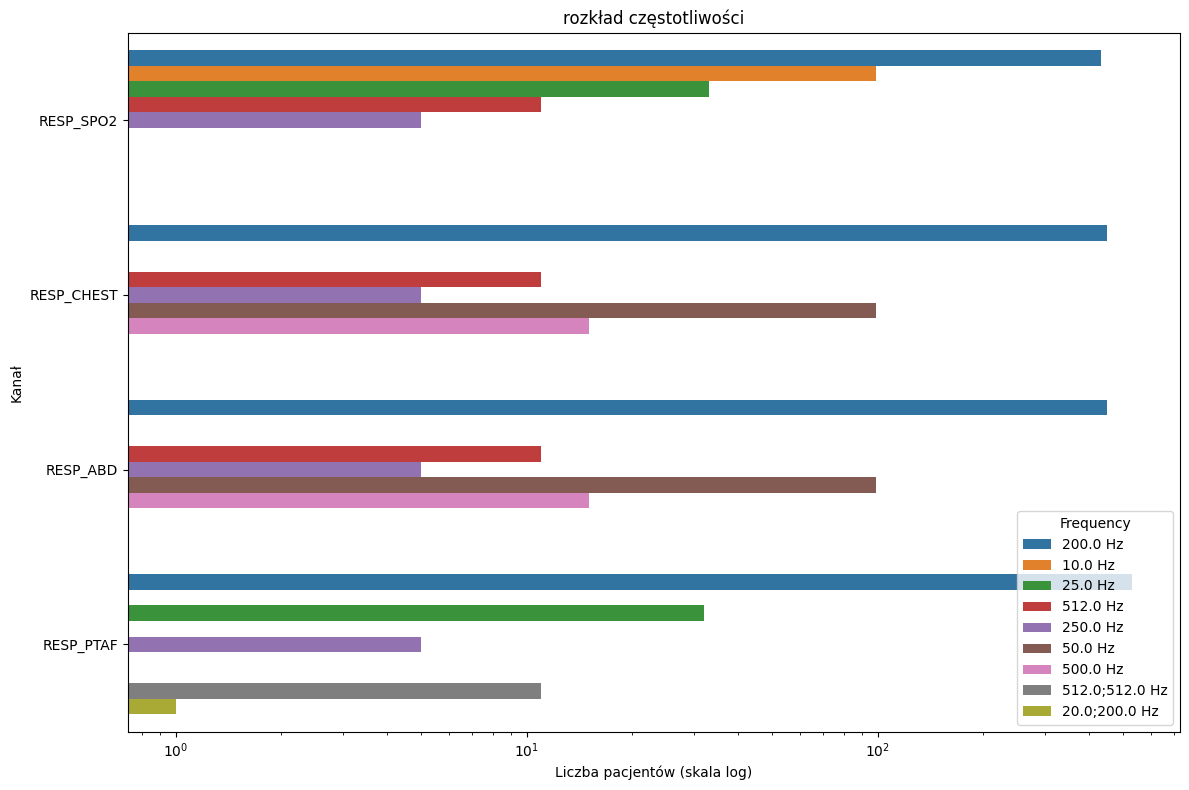

In [21]:
resp_cols = [
    'resp_spo2_',
    'resp_chest_',
    'resp_abd_',
    'resp_ptaf_'
]

plot_sampling_uencies(df_cleaned, resp_cols)

Kanały oddechowe są najbardziej zróżnicowane pod względem częstotliwości nagrywania. W ich przypadku standardy AASM nie są tak jednolite jak w przypadku sygnałów elektrofizjologicznych i dla różnych kanałów zalecane są różne częstotlwiości. Dodatkowo sygnały oddechowe analizuje się głównie pod kątem morfologii w domenie czasu, dlatego wymagają one wyższej, zalecanej częstotliwości próbkowania, aby wiernie zachować kształt fali i precyzyjnie rejestrować przesunięcia fazowe. Biorąc to pod uwagę dla każdego kanału zostanie zastosowane inna strategia przepróbkowania:
 - spo2: W tym wypadku zalecane jest minimum 10Hz a najoptymalniej - 25. Zdecydowana większość kanałów jest nagrana w częstotliwościach większych, co pozwoli na łatwe zmniejszenie częstotliwości w tych kanałach. W celu zachowania pełnej informacji medycznej, kanały nagrane w 10 Hz zostaną zinterpolowane do 25 Hz. Takie zwiększenie częstotliwości nie wprowadzi znacznego szumu oraz nie będzie wymagało dużych nakładów mocy obliczeniowe.
 - chest i abd: Zgodnie z wytycznymi optymalną częstotliwością próbkowania dla tych sygnałów jest 100 Hz. Mimo że w zbiorze nie ma nagrań o tej konkretnej wartości (dominuje 200 Hz, a minimum to 50 Hz), przyjęcie jej za standard jest w pełni uzasadnione. Zmniejszenie częstotliwości nagrań 200-hercowych zredukuje wymiarowość danych bez utraty informacji medycznej, natomiast zwiększenie nielicznych sygnałów 50-hercowych do 100 Hz ujednolici dane do późniejszej analizy.
 - ptaf: Zgodnie z wytycznymi optymalną częstotliwością dla przepływu powietrza jest 100 Hz, co pozwala zachować szczegóły krzywej sygnału. Sygnały o wyższych częstotliwościach zostaną poddane przepróbkowaniu , a rzadsze o niższych wartościach zinterpolowane w górę. W zbiorze zidentyfikowano jeden plik z błędnym nagłówkiem 20.0; 200.0 Hz. Na podstawie wcześniejszej analizy ustalono jego rzeczywistą częstotliwość na 20 Hz, dlatego on również zostanie przepróbkowany do docelowych 100 Hz, zapewniając spójność wymiarową danych dla modelu.

W każdym badanym kanale aparatura mierzyła sygnały w różnych jednostkach. Niestety w żadnym w kanale jednostki te nie są możliwe do przeliczenia i ujednolicenia. Niektóre kanały mają jednostkę zupełnie niedopasowaną do mierzonego zjawiska, np. ciśnienie jest zmierzone w uV, co oznacza, że zapisywały one surowy sygnał elektryczny jaki dostawały od apratury pomiarowej lub jednostki zostały fałszywie zapisane. Część pomiarów abd i chest została wykonana w uniwersalnej jednostce (u), więc jest niemożliwa do przeliczenia bez zajomości specyfikacji sprzętu pomiarowago. Ze względu na to, że w kanałach oddechowych najważniejszy jest kształt krzywej w celu identyfikacji wdechów i wydechów, wszystkie kanały zostaną poddane normalizacji Z-Score, dzięki czemu zostaną zachowane wszystkie informacje istotne informacje przy jednoczesnym uniknięciu potencjalnych błędów, wnikających z niespójności jednostek pomiarowych. Jednakże kanał spo2 nie może zostać poddany normalizacji ze względu na istotność bezwględnych wartości zawartych w sygnale.

In [22]:
spo2_uv = df_cleaned[df_cleaned['resp_spo2_DIM'] == 'uV'].copy()
in_range_0_100 = 0
exceeds_100 = 0
has_negative = 0
errors = 0
exceeds_100_files = []
has_negative_files = []
error_files = []

for idx, row in spo2_uv.iterrows():
    bids_folder = row['BidsFolder']
    site_id = row['SiteID']
    session_id = row['SessionID']
    source_channel = row['resp_spo2_SOURCE']
    
    file_name = f"{bids_folder}_ses-{session_id}.edf"
    file_path = os.path.join(base_path, str(site_id), file_name)

    try:
        edf = pyedflib.EdfReader(file_path)
        signal_labels = edf.getSignalLabels()
        
        if source_channel not in signal_labels:
            edf.close()
            errors += 1
            error_files.append(file_path)
            continue
        
        channel_idx = signal_labels.index(source_channel)
        signal = edf.readSignal(channel_idx)
        edf.close()
        
        min_val = np.min(signal)
        max_val = np.max(signal)
        
        if min_val < 0:
            has_negative += 1
            has_negative_files.append(file_path)
        
        if max_val > 100:
            exceeds_100 += 1
            exceeds_100_files.append(file_path)
        
        if min_val >= 0 and max_val <= 100:
            in_range_0_100 += 1
        
    except Exception as e:
        errors += 1
        error_files.append(file_path)

print(f"Kanały poprawne (0-100%): {in_range_0_100}")
print(f"Kanały przekraczające 100: {exceeds_100}")
print(f"Kanały z wartościami ujemnymi: {has_negative}")

Kanały poprawne (0-100%): 446
Kanały przekraczające 100: 2
Kanały z wartościami ujemnymi: 0


Ze względu na fakt, że znakomita większośc kanałów spo2 zmierzonych w uV zawiera wyłącznie wartości z przedziału 0-100, można wywnioskować, że jest to zwyczajny błąd w nagłówku pliku. Zmierzone wartości zostają uznane jako standardowa saturacja wyrażona w procentach. Pozostałe 2 przypadki, w których wartości przekroczyły wartość zostaną zbadane indywidualnie.

/tmp/ipykernel_23837/2814530891.py:41: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.tight_layout()
/home/emil/.local/lib/python3.10/site-packages/IPython/core/pylabtools.py:170: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


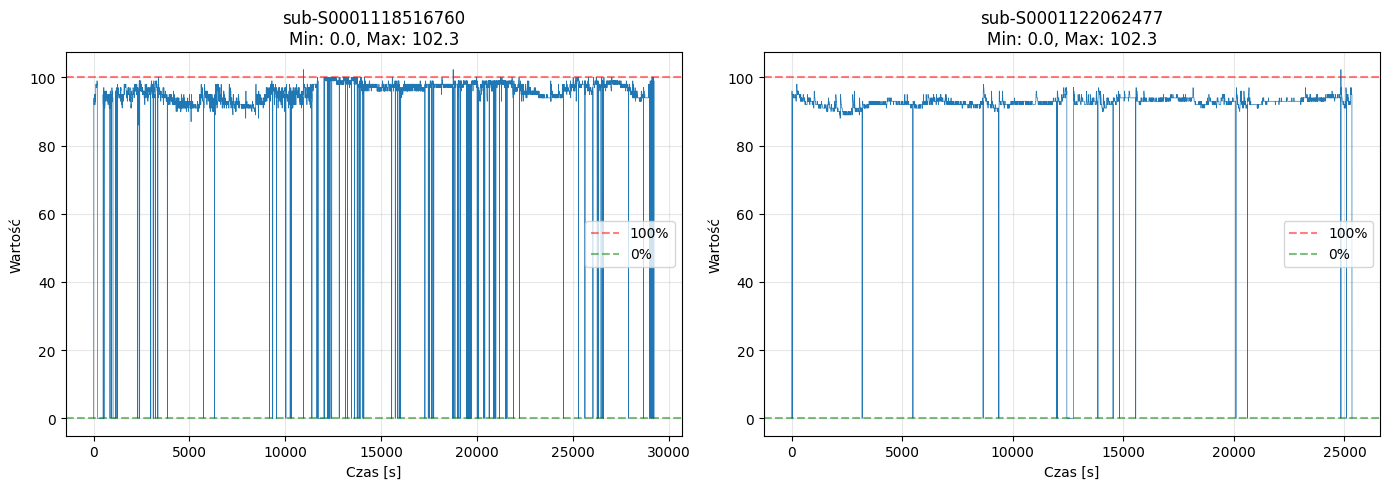

In [23]:
import matplotlib.pyplot as plt

exceeds_100_names = {os.path.basename(p) for p in exceeds_100_files}

df_exceed_100 = df_cleaned[df_cleaned.apply(
    lambda row: f"{row['BidsFolder']}_ses-{row['SessionID']}.edf" in exceeds_100_names,
    axis=1
)]

n = len(df_exceed_100)
fig, axes = plt.subplots(1, n, figsize=(7 * n, 5), squeeze=False)
axes = axes[0]

for i, (idx, row) in enumerate(df_exceed_100.iterrows()):
    bids_folder = row['BidsFolder']
    site_id = row['SiteID']
    session_id = row['SessionID']
    source_channel = row['resp_spo2_SOURCE']

    file_name = f"{bids_folder}_ses-{session_id}.edf"
    file_path = os.path.join(base_path, str(site_id), file_name)

    edf = pyedflib.EdfReader(file_path)
    signal_labels = edf.getSignalLabels()
    channel_idx = signal_labels.index(source_channel)
    signal = edf.readSignal(channel_idx)
     = edf.getSampleuency(channel_idx)
    edf.close()

    time = np.arange(len(signal)) / 

    axes[i].plot(time, signal, linewidth=0.5)
    axes[i].set_title(f"{bids_folder}\nMin: {np.min(signal):.1f}, Max: {np.max(signal):.1f}")
    axes[i].set_xlabel('Czas [s]')
    axes[i].set_ylabel('Wartość')
    axes[i].axhline(y=100, color='r', linestyle='--', alpha=0.5, label='100%')
    axes[i].axhline(y=0, color='g', linestyle='--', alpha=0.5, label='0%')
    axes[i].grid(True, alpha=0.3)
    axes[i].legend()

plt.tight_layout()
plt.show()

Wykres jednoznacznie pokazuje, że wartości powyżej 100% są bardzo znikome i stanowią pojedyncze artefakty, które wynikają prawdopodobnie z szumu sprzętowego lub źle skalibrowanej aparatury. Duża ilość spadków saturacji do 0 na pierwszym wykresie sugeruje ogólne problemy ze sprzętem mierzącym saturację podczas tego badania. Na potrzeby czyszczenia danych sygnały te zostają również uznane za popranwnie zmierzoną saturację, wyrażoną w procentach, a błędna jednostka 'uV' w metadanych wymaga korekty na '%'.
### 3.3 Podsumowanie
Analiza wykazała, że każdy rodzaj sygnału i każdy kanał zawiera niespójności w częstotliwości próbkowania. Aby zmniejszyć rozmiar danych oraz poprawić optymalizację obliczeń, kanałom zawierającym sygnały elektrofizjologiczne częstotliwość zostanie dostosowana do minimum zalecanego przez AASM (200 Hz). Kanały elektrofizjologiczne mają ujednolicone jednostki, więc nie wymagają one ingerencji w tym zakresie. Kanały oddechowe wymagają innego podejścia. Ze względu na ich niejednorodne jednostki, których nie można między sobą przeliczyć, kanały te zostaną poddane standaryzacji, w celu zachowania pełnej informacji o kształcie sygnału. Wyjątkiem jest kanał spo2, w którym konkretne wartości bezwględne mają znaczenie. Ponadto kanały spo2 mają niepoprawnie nazwane jednostki w nagłówkach i będzie to musiało zostać skorygowane. Niektóre kanały oddechowe zostały nagrane w niższej częstotliwości niż docelowa, dlatego zostaną zinterpolowane w górę w celu ujednolicenia wymiarowości danych (spo2 do 25Hz, pozostałe do 100 Hz).

## 4. Podsumowanie i pipelie przetwarzający
Na podstawie powyższej analizy zaprojektowano pipeline sterowany, który przetwarza dane z warstwy bronze do warstwy silver. Decyzje podejmowane są na podstawie metadata.csv, a następnie aplikowane do surowych sygnałów. Pipeline składa się z czterech etapów.

### Etap 1 — Filtrowanie i rekonstrukcja braków
Centralnym elementem jest scentralizowana "tablica prawdy" — zbiór reguł opisujących, jak każdy kanał może zostać odtworzony lub zastąpiony:

- **Rekonstrukcja kanałów bipolarnych z unipolarnych** — kanał bipolarny (np. eeg_f3_m2) to różnica dwóch elektrod unipolarnych (f3 − m2). Jeśli kanał bipolarny jest pusty, ale obie składowe są dostępne, da się go odtworzyć. Dotyczy kanałów EEG (6 par), EOG (2 pary, z mastoidami eeg_m1/eeg_m2), brody oraz EMG nóg (lat/rat z par lleg/rleg).
- **Substytucja zgodnie ze standardem AASM** — dla przepływu powietrza, przy braku ptaf, dopuszcza się zastąpienie kanałem airflow lub cflow (reguła OR), .

Wiersz jest oznaczany jako nieodtwarzalny (do odrzucenia), jeśli ma brak w którymkolwiek kanale krytycznym (human/algo), albo brak w kanale bipolarnym EEG/EMG nóg niemożliwy do odtworzenia z unipolarnych, albo brak w ptaf niemożliwy do zastąpienia. W efekcie odrzuconych zostaje 42 pacjentów (≈ 6,75 % z 622), pozostaje 580 pacjentów.

Braki w kanałach eog oraz chin_emg_chin1_chin2 (broda — nieodtwarzalny w 100 %) są celowo pozostawione do indywidualnego traktowania na etapie ekstrakcji cech, ponieważ ich pełne wykluczenie oznaczałoby utratę ~20 % zbioru.

### Etap 2 — Rozwiązanie konfliktów mapowania
Dla wierszy, w których kanał źródłowy zawiera kilka kanałów (rozdzielonych ';'), pipeline otwiera plik EDF, wczytuje fragment sygnału i wybiera najlepszy kanał. Strategia zależy od typu sygnału:

- **Kanały oddechowe** — kryteria: Konflikty oddechowe rejestrują to samo zjawisko, więc stosowana jest hierarchia: priorytet PTAF, następnie Pressure, a gdy oba kanały są jednostajne — wiersz jest odrzucany.
- **Kanały ECG** — wariancja jest tu myląca, dlatego używane są statystyki wyższych rzędów: SQI_hos = kurtoza * |skośność|. Wybierany jest kanał o najwyższej wartości (zwykle ECG-LA), ale decyzja jest podejmowana per-pacjent.

### Etap 3 — Ujednolicenie częstotliwości próbkowania

| Grupa kanałów | Częstotliwość docelowa | Strategia |
|---|---|---|
| Oceny human / algorithmic | bez zmian | już jednolite i wzajemnie spójne |
| EEG | 200 Hz | przepróbkowanie w dół do standardu AASM |
| EOG, EMG, ECG | 200 Hz | przepróbkowanie w dół do standardu AASM |
| SpO₂ | 25 Hz | przepróbkowanie w dół z wyższych; interpolacja z 10 Hz |
| Chest, Abdomen | 100 Hz | przepróbkowanie w dół lub w interpolacja z 50 Hz |
| PTAF | 100 Hz | przepróbkowanie w dół lub w interpolacja z 25 lub 20 Hz |

### Etap 4 — Ujednolicenie i normalizacja jednostek
- **Kanały elektrofizjologiczne (EEG, EOG, EMG, ECG)** — wszystkie w uV, bez zmian.
- **Kanały oddechowe (PTAF, Chest, Abdomen)** — jednostki niespójne i nieprzeliczalne między sobą; ponieważ liczy się kształt krzywej, stosowana jest normalizacja Z-score.
- **SpO₂** — wyjątek: normalizacja niedozwolona (istotne są wartości bezwzględne). Kanały błędnie opisane jako uV zawierają w ~99 % wartości 0–100, więc to błąd nagłówka — jednostka jest korygowana na '%', a wartości zachowywane. Pojedyncze odczyty > 100 % to artefakty sprzętowe.

### Wynik
Warstwa silver zawiera 580 pacjentów z kompletnymi kanałami krytycznymi, ujednoliconą częstotliwością w obrębie każdej grupy sygnałów, znormalizowanymi kanałami oddechowymi i poprawionymi jednostkami SpO₂. Zbiór jest gotowy do ekstrakcji cech i trenowania modeli. 

**Lista 31 kanałów, która ostatecznie znajdzie się w warstwie silver:**  eeg_f3_m2, eeg_f4_m1, eeg_c3_m2, eeg_c4_m1, eeg_o1_m2, eeg_o2_m1, eog_e1_m2, eog_e2_m1, chin_emg_chin1_chin2, leg_emg_lat, leg_emg_rat, ecg_ecg, resp_chest, resp_abd, resp_ptaf, resp_spo2, _arousal_expert, limb_expert, resp_expert, stage_expert, arousal_caisr, limb_caisr, resp_caisr, stage_caisr, caisr_prob_w, caisr_prob_r, caisr_prob_n1, caisr_prob_n2, caisr_prob_n3, caisr_prob_arous, caisr_prob_no-ar
